<div dir="rtl" align="right">
<h1>فاز دوم پروژه آمار: احتمال و توزیع‌های احتمالی 
<hr>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# ۱. بارگذاری و ادغام ۸ فایل موضوعی   
data_dir = Path("../data")

lux_df = pd.read_sas(data_dir / "LUX_L.xpt", format="xport")
lux_cols = [c for c in ["SEQN", "LUAXSTAT", "LUARXNC", "LUANMVGP", "LUXSMED", "LUXSIQR", "LUXSIQRM", "LUXCAPM"] if c in lux_df.columns]
df_merged = lux_df[lux_cols].copy()

other_files_vars = {
    "DEMO_L.xpt": ["SEQN", "RIDAGEYR", "RIAGENDR", "WTMEC2YR"],
    "CBC_L.xpt": ["SEQN", "LBDNENO", "LBDLYMNO"],
    "BMX_L.xpt": ["SEQN", "BMXBMI"],
    "BPXO_L.xpt": ["SEQN", "BPXOSY1"],
    "GHB_L.xpt": ["SEQN", "LBXGH"],
    "TCHOL_L.xpt": ["SEQN", "LBXTC"],
    "BIOPRO_L.xpt": ["SEQN", "LBXSATSI", "LBXSASSI"]
}

for fname, cols in other_files_vars.items():
    fpath = data_dir / fname
    temp_df = pd.read_sas(fpath, format="xport")[cols]
    df_merged = pd.merge(df_merged, temp_df, on="SEQN", how="right" if fname == "DEMO_L.xpt" else "left")

# ۲. محاسبه شاخص التهاب سیستمیک و اعمال فیلترهای پایه فاز اول
df_merged["NLR"] = np.where(
    df_merged["LBDLYMNO"] > 0,
    df_merged["LBDNENO"] / df_merged["LBDLYMNO"],
    np.nan
)

n_total = len(df_merged)
df_adults = df_merged[df_merged["RIDAGEYR"] >= 20].copy()
n_under20 = n_total - len(df_adults)

df_mec = df_adults[df_adults["WTMEC2YR"] > 0].copy()
n_no_mec = len(df_adults) - len(df_mec)

df_phase1 = df_mec.dropna(subset=["LUXSMED", "NLR"]).copy()
n_missing_main = len(df_mec) - len(df_phase1)

# ۳. اعمال ۳ پارامتر کنترل کیفیت الاستوگرافی کبد (ناشتایی، تعداد دفعات تست، واریانس/تغییرپذیری)
n_fasting_fail = int((df_phase1["LUARXNC"] == 1).sum())
n_measures_fail = int(df_phase1["LUANMVGP"].isin([1, 2]).sum())
n_var_fail = int((df_phase1["LUXSIQRM"] >= 30).sum())

cond_quality = (
    (df_phase1["LUAXSTAT"] == 1) &
    (~df_phase1["LUANMVGP"].isin([1, 2])) &
    (df_phase1["LUXSIQRM"] < 30)
)

df_qc = df_phase1[cond_quality].copy()
n_qc_dropped = len(df_phase1) - len(df_qc)

# ۴. حذف ردیف‌های دارای داده گمشده در متغیرهای فرعی و کنترلی
secondary_cols = ["LUXCAPM", "BMXBMI", "BPXOSY1", "LBXGH", "LBXTC", "LBXSATSI", "LBXSASSI"]
all_analysis_cols = ["RIDAGEYR", "RIAGENDR", "WTMEC2YR", "LUXSMED", "NLR"] + secondary_cols

df_clean = df_qc.dropna(subset=all_analysis_cols).copy().reset_index(drop=True)
n_sec_dropped = len(df_qc) - len(df_clean)

print("\n=== جریان گام‌به‌گام تعیین حجم نمونه تحلیلی نهایی (فاز دوم - موارد کاملاً بدون داده گمشده) ===")
print(f"\u202b۱. تعداد کل شرکت‌کنندگان پس از ادغام ۸ فایل: {n_total} نفر\u202c")
print(f"\u202b۲. حذف افراد زیر ۲۰ سال: {n_under20} نفر (باقی‌مانده بزرگسالان: {len(df_adults)} نفر)\u202c")
print(f"\u202b۳. حذف بزرگسالان فاقد وزن معاینه (WTMEC2YR = 0): {n_no_mec} نفر (باقی‌مانده: {len(df_mec)} نفر)\u202c")
print(f"\u202b۴. حذف به دلیل داده گمشده در متغیرهای اصلی (LUXSMED یا NLR): {n_missing_main} نفر (نمونه فاز اول: {len(df_phase1)} نفر)\u202c")
print(f"\u202b۵. حذف به دلیل عدم احراز ۳ پارامتر کیفیت الاستوگرافی کبد: {n_qc_dropped} نفر (باقی‌مانده باکیفیت: {len(df_qc)} نفر)\u202c")
print(f"\u202b   - پارامتر ۱ (زمان ناشتایی کمتر از ۳ ساعت | LUARXNC == 1): {n_fasting_fail} نفر\u202c")
print(f"\u202b   - پارامتر ۲ (تعداد اندازه‌گیری معتبر کمتر از ۱۰ بار): {n_measures_fail} نفر\u202c")
print(f"\u202b   - پارامتر ۳ (تغییرپذیری بالای اندازه‌گیری‌ها | IQR/Median >= 30%): {n_var_fail} نفر\u202c")
print(f"\u202b۶. حذف به دلیل داده گمشده در متغیرهای فرعی و کنترلی: {n_sec_dropped} نفر\u202c")
print(f"\u202b==> ۷. حجم نمونه تحلیلی نهایی و کاملاً بدون داده گمشده (df_clean): {len(df_clean)} نفر\u202c\n")


=== جریان گام‌به‌گام تعیین حجم نمونه تحلیلی نهایی (فاز دوم - موارد کاملاً بدون داده گمشده) ===
‫۱. تعداد کل شرکت‌کنندگان پس از ادغام ۸ فایل: 11933 نفر‬
‫۲. حذف افراد زیر ۲۰ سال: 4124 نفر (باقی‌مانده بزرگسالان: 7809 نفر)‬
‫۳. حذف بزرگسالان فاقد وزن معاینه (WTMEC2YR = 0): 0 نفر (باقی‌مانده: 7809 نفر)‬
‫۴. حذف به دلیل داده گمشده در متغیرهای اصلی (LUXSMED یا NLR): 2449 نفر (نمونه فاز اول: 5360 نفر)‬
‫۵. حذف به دلیل عدم احراز ۳ پارامتر کیفیت الاستوگرافی کبد: 319 نفر (باقی‌مانده باکیفیت: 5041 نفر)‬
‫   - پارامتر ۱ (زمان ناشتایی کمتر از ۳ ساعت | LUARXNC == 1): 100 نفر‬
‫   - پارامتر ۲ (تعداد اندازه‌گیری معتبر کمتر از ۱۰ بار): 17 نفر‬
‫   - پارامتر ۳ (تغییرپذیری بالای اندازه‌گیری‌ها | IQR/Median >= 30%): 179 نفر‬
‫۶. حذف به دلیل داده گمشده در متغیرهای فرعی و کنترلی: 427 نفر‬
‫==> ۷. حجم نمونه تحلیلی نهایی و کاملاً بدون داده گمشده (df_clean): 4614 نفر‬



<div dir="rtl" align="right">
<h3>جمع‌بندی آماده‌سازی داده، تعیین حجم نمونه نهایی و علت حذف داده‌های گمشده</h3>
در فاز اول پروژه، با اعمال شرط سنی (بزرگسالان ۲۰ سال و بالاتر)، داشتن وزن معاینه معتبر (<code>WTMEC2YR > 0</code>) و حذف مقادیر گمشده در دو متغیر اصلی (<code>LUXSMED</code> و <code>NLR</code>)، نمونه اولیه شامل ۵,۳۶۰ شرکت‌کننده به دست آمد.<br><br>
به منظور افزایش دقت اندازه‌گیری و یکدست‌سازی کامل فضای نمونه در تمامی تحلیل‌ها، دو مرحله پالایش تکمیلی اعمال گردید:<br>
<b>۱. اعمال معیارهای کنترل کیفیت الاستوگرافی کبد:</b> ۳۱۹ مشاهده که فاقد معیارهای کیفیت معاینه کامل (<code>LUAXSTAT == 1</code>) بودند — به دلیل ناشتایی کمتر از ۳ ساعت (<code>LUARXNC == 1</code> شامل ۱۰۰ نفر)، تعداد دفعات اندازه‌گیری معتبر کمتر از ۱۰ بار (<code>LUANMVGP</code> با کدهای ۱ و ۲ شامل ۱۷ نفر) یا تغییرپذیری و واریانس بالای اندازه‌گیری‌ها (<code>LUXSIQRM >= 30%</code> شامل ۱۷۹ نفر) — کنار گذاشته شدند تا ۵,۰۴۱ مشاهده باکیفیت باقی بمانند.<br>
<b>۲. حذف کامل مقادیر گمشده در متغیرهای فرعی و کنترلی:</b> به منظور انجام تحلیل موارد کامل روی یک فضای نمونه واحد، ۴۲۷ مشاهده که در هر یک از متغیرهای فرعی (<code>LUXCAPM</code>، <code>BMXBMI</code>، <code>BPXOSY1</code>، <code>LBXGH</code>، <code>LBXTC</code>، <code>LBXSATSI</code> و <code>LBXSASSI</code>) دارای مقدار گمشده بودند نیز حذف گردیدند تا در مجموعه داده تحلیلی نهایی (<code>df_clean</code>) هیچ مقدار گمشده‌ای در هیچ متغیری وجود نداشته باشد.<br><br>
<b>دلایل آماری و علمی حذف داده‌های گمشده (روش تحلیل موارد کامل):</b><br>
• <b>یکپارچگی فضای نمونه (Ω) در نظریه احتمال:</b> در محاسبات فاز دوم (شامل احتمال‌های حاشیه‌ای، مشترک، شرطی، قضیه بیز و کوواریانس)، تمامی رویدادها و متغیرهای تصادفی باید بر روی یک فضای نمونه واحد و ثابت تعریف شوند. وجود داده‌های گمشده باعث تغییر مخرج کسر (N) از یک متغیر به متغیر دیگر شده و سازگاری ریاضی روابط احتمالی (مانند <code>P(A ∩ B)</code> و قانون احتمال کل) را مختل می‌کند.<br>
• <b>جلوگیری از اریبی و تحریف توزیع واقعی داده ها :</b> در متغیرهای زیستی و آزمایشگاهی (مانند سفتی کبد، شاخص التهاب و آنزیم‌های کبدی)، جایگذاری مقادیر گمشده با مقادیر مصنوعی (نظیر میانگین یا میانه) باعث کاهش کاذب واریانس، تغییر شکل واقعی چولگی توزیع‌ها و ایجاد خطا در برآورد احتمال رویدادهای حدی و رابطه واقعی بین متغیرها می‌شود.<br>
• <b>کفایت بالای حجم نمونه باقی‌مانده:</b> پس از حذف موارد ناقص، حجم نمونه ۴,۶۱۴ نفری همچنان بسیار بزرگ بوده و از توان و دقت آماری کاملاً کافی برای محاسبه دقیق احتمال ها و شاخص های آماری برخوردار است.
<hr>
</div>

<div dir="rtl" align="right">
<h2>تسک مشترک ۱: تعریف رویدادها و متغیرهای تصادفی</h2>
<b>تعریف واحد مشاهده و فضای نمونه (Ω):</b><br> پس از اعمال فیلترهای کنترل کیفیت الاستوگرافی کبد و حذف کامل تمامی مقادیر گمشده ، فضای نمونه شامل <b>۴,۶۱۴ ردیف</b> موجود در مجموعه داده تحلیلی نهایی (<code>df_clean</code>) است. هر <b>مشاهده</b> در این فضای نمونه، دقیقاً متناظر با <b>یک شرکت‌کننده بزرگسال مستقل (۲۰ سال و بالاتر) دارای معاینه معتبر در پیمایش NHANES (۲۰۲۱–۲۰۲۳)</b> است که در مجموعه داده با شناسه یکتای <code>SEQN</code> در یک سطر مجزا مشخص می‌شود.<br><br>
<b>الف) تعریف رویدادهای تصادفی :</b><br>
• <b>رویداد A (ابتلا به فیبروز پیشرفته کبدی - Advanced Fibrosis):</b> شامل تمام مشاهداتی (ردیف‌هایی با شناسه <code>SEQN</code>) است که در ستون سفتی کبد (<code>LUXSMED</code> از فایل <code>LUX_L</code>) دارای مقدار برابر یا بیشتر از آستانه بالینی ۸.۲ کیلوپاسکال باشند (<code>LUXSMED >= 8.2</code>). وقوع این رویداد در دیتافریم با ستون دودویی <code>Event_A_Fibrosis</code> (مقدار <code>1</code> برای وقوع و <code>0</code> برای عدم وقوع در آن مشاهده) ثبت شده است.<br>
• <b>رویداد B (التهاب سیستمیک بالا - High NLR):</b> شامل تمام مشاهداتی (ردیف‌هایی با شناسه <code>SEQN</code>) است که در متغیر نسبت نوتروفیل به لنفوسیت (<code>NLR</code> حاصل از فایل <code>CBC_L</code>) دارای مقدار برابر یا بیشتر از آستانه بالینی ۳.۰ باشند (<code>NLR >= 3.0</code>). این رویداد با ستون دودویی <code>Event_B_HighNLR</code> (مقدار <code>1</code> برای وقوع و <code>0</code> برای عدم وقوع) مشخص می‌شود.<br>
• <b>رویدادهای زیرگروهی G (جنسیت مرد) و S (سالمندی ۶۰ سال و بالاتر):</b> برای تحلیل احتمال‌های شرطی در زیرگروه‌ها، رویداد <code>G</code> شامل مشاهداتی است که در ستون <code>RIAGENDR</code> دارای کد <code>1</code> (مرد) هستند (<code>Event_G_Male</code>) و رویداد <code>S</code> شامل مشاهداتی است که در ستون سن (<code>RIDAGEYR</code>) دارای مقدار ۶۰ سال و بالاتر هستند (<code>Event_S_Senior</code>).<br><br>
<b>ب) تعریف متغیرهای تصادفی :</b><br>
• <b>متغیر تصادفی پیوسته Y (سفتی کبد):</b> تابعی است که به هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>)، مقدار عددی پیوسته ثبت‌شده در ستون <code>LUXSMED</code> همان ردیف را بر حسب کیلوپاسکال (<code>kPa</code>) نسبت می‌دهد.<br>
• <b>متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک):</b> تابعی است که به هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>)، مقدار عددی پیوسته ثبت‌شده در ستون <code>NLR</code> همان ردیف را نسبت می‌دهد.<br>
• <b>متغیر تصادفی گسسته برنولی I_A (نشانگر فیبروز پیشرفته):</b> تابعی گسسته با مقادیر <code>{0, 1}</code> است که به هر مشاهده (ردیف <code>SEQN</code>) در صورت وقوع رویداد فیبروز پیشرفته (<code>LUXSMED >= 8.2</code>) عدد <code>1</code> و در غیر این صورت عدد <code>0</code> را نسبت می‌دهد.
</div>

In [2]:
# ۱. تعریف ستون‌های نشانگر (0 و 1) برای رویدادها به ازای هر مشاهده (SEQN) در df_clean
df_clean["Event_A_Fibrosis"] = (df_clean["LUXSMED"] >= 8.2).astype(int)
df_clean["Event_B_HighNLR"] = (df_clean["NLR"] >= 3.0).astype(int)
df_clean["Event_G_Male"] = (df_clean["RIAGENDR"] == 1).astype(int)
df_clean["Event_S_Senior"] = (df_clean["RIDAGEYR"] >= 60).astype(int)

# ۲. جدول خلاصه رویدادها و متغیرهای تصادفی در فضای نمونه ۴۶۱۴ نفری
task1_summary = pd.DataFrame({
    "نماد و عنوان در مدل احتمالی": [
        "رویداد A / متغیر برنولی I_A (فیبروز پیشرفته کبدی)",
        "رویداد B / متغیر برنولی I_B (التهاب سیستمیک بالا)",
        "رویداد G (زیرگروه جنسیت مرد)",
        "رویداد S (زیرگروه سنی ۶۰ سال و بالاتر)",
        "متغیر تصادفی پیوسته Y (سفتی کبد)",
        "متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک)"
    ],
    "ستون و شرط متناظر در هر ردیف داده (SEQN)": [
        "LUXSMED >= 8.2 kPa (ستون Event_A_Fibrosis)",
        "NLR >= 3.0 (ستون Event_B_HighNLR)",
        "RIAGENDR == 1 (ستون Event_G_Male)",
        "RIDAGEYR >= 60 (ستون Event_S_Senior)",
        "مقدار کمی ستون LUXSMED (بر حسب kPa)",
        "مقدار کمی ستون NLR (نسبت نوتروفیل به لنفوسیت)"
    ],
    "نوع در نظریه احتمال": [
        "رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1)",
        "رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1)",
        "رویداد طبقه‌ای دودویی (0 و 1)",
        "رویداد طبقه‌ای دودویی (0 و 1)",
        "متغیر تصادفی کمی پیوسته",
        "متغیر تصادفی کمی پیوسته"
    ],
    "تعداد کل مشاهدات (N)": [len(df_clean)] * 6,
    "فراوانی وقوع (کد 1) یا دامنه مقادیر": [
        f"{int(df_clean['Event_A_Fibrosis'].sum())} نفر ({df_clean['Event_A_Fibrosis'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_B_HighNLR'].sum())} نفر ({df_clean['Event_B_HighNLR'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_G_Male'].sum())} نفر ({df_clean['Event_G_Male'].mean()*100:.2f}%)",
        f"{int(df_clean['Event_S_Senior'].sum())} نفر ({df_clean['Event_S_Senior'].mean()*100:.2f}%)",
        f"دامنه: [{df_clean['LUXSMED'].min():.1f} تا {df_clean['LUXSMED'].max():.1f}] | میانگین: {df_clean['LUXSMED'].mean():.2f}",
        f"دامنه: [{df_clean['NLR'].min():.2f} تا {df_clean['NLR'].max():.2f}] | میانگین: {df_clean['NLR'].mean():.2f}"
    ]
})

print(f"\u202b--- ۱. جدول مشخصات رویدادها و متغیرهای تصادفی در فضای نمونه نهایی (N = {len(df_clean)}) ---\u202c")
display(task1_summary)

# ۳. نمایش مصداق عینی از مشاهدات واقعی داده (بر اساس شناسه SEQN)
sample_obs = df_clean[[
    "SEQN", "RIDAGEYR", "RIAGENDR", "LUXSMED", "NLR",
    "Event_A_Fibrosis", "Event_B_HighNLR", "Event_G_Male", "Event_S_Senior"
]].head(6).copy()

sample_obs["SEQN"] = sample_obs["SEQN"].astype(int)
sample_obs["RIDAGEYR"] = sample_obs["RIDAGEYR"].astype(int)
sample_obs["RIAGENDR"] = sample_obs["RIAGENDR"].map({1: "مرد (1)", 2: "زن (2)"})
sample_obs["NLR"] = sample_obs["NLR"].round(2)

sample_obs.columns = [
    "شناسه مشاهده (SEQN)",
    "سن (RIDAGEYR)",
    "جنسیت (RIAGENDR)",
    "متغیر پیوسته Y (LUXSMED)",
    "متغیر پیوسته X (NLR)",
    "وقوع رویداد A (فیبروز >= 8.2)",
    "وقوع رویداد B (التهاب >= 3.0)",
    "وقوع رویداد G (مرد)",
    "وقوع رویداد S (سن >= 60)"
]

print(f"\n\u202b--- ۲. نمونه عینی تناظر مشاهدات داده (ردیف‌های SEQN) با مقادیر متغیرهای تصادفی و وقوع رویدادها ---\u202c")
display(sample_obs)

‫--- ۱. جدول مشخصات رویدادها و متغیرهای تصادفی در فضای نمونه نهایی (N = 4614) ---‬


,نماد و عنوان در مدل احتمالی,ستون و شرط متناظر در هر ردیف داده (SEQN),نوع در نظریه احتمال,تعداد کل مشاهدات (N),فراوانی وقوع (کد 1) یا دامنه مقادیر
0,رویداد A / متغیر برنولی I_A (فیبروز پیشرفته کبدی),LUXSMED >= 8.2 kPa (ستون Event_A_Fibrosis),رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1),4614,538 نفر (11.66%)
1,رویداد B / متغیر برنولی I_B (التهاب سیستمیک بالا),NLR >= 3.0 (ستون Event_B_HighNLR),رویداد طبقه‌ای / متغیر گسسته دودویی (0 و 1),4614,769 نفر (16.67%)
2,رویداد G (زیرگروه جنسیت مرد),RIAGENDR == 1 (ستون Event_G_Male),رویداد طبقه‌ای دودویی (0 و 1),4614,2108 نفر (45.69%)
3,رویداد S (زیرگروه سنی ۶۰ سال و بالاتر),RIDAGEYR >= 60 (ستون Event_S_Senior),رویداد طبقه‌ای دودویی (0 و 1),4614,2061 نفر (44.67%)
4,متغیر تصادفی پیوسته Y (سفتی کبد),مقدار کمی ستون LUXSMED (بر حسب kPa),متغیر تصادفی کمی پیوسته,4614,دامنه: [1.5 تا 75.0] | میانگین: 6.13
5,متغیر تصادفی پیوسته X (شاخص التهاب سیستمیک),مقدار کمی ستون NLR (نسبت نوتروفیل به لنفوسیت),متغیر تصادفی کمی پیوسته,4614,دامنه: [0.30 تا 16.00] | میانگین: 2.20



‫--- ۲. نمونه عینی تناظر مشاهدات داده (ردیف‌های SEQN) با مقادیر متغیرهای تصادفی و وقوع رویدادها ---‬


,شناسه مشاهده (SEQN),سن (RIDAGEYR),جنسیت (RIAGENDR),متغیر پیوسته Y (LUXSMED),متغیر پیوسته X (NLR),وقوع رویداد A (فیبروز >= 8.2),وقوع رویداد B (التهاب >= 3.0),وقوع رویداد G (مرد),وقوع رویداد S (سن >= 60)
0,130378,43,مرد (1),9.5,1.16,1,0,1,0
1,130379,66,مرد (1),3.9,2.25,0,0,1,1
2,130380,44,زن (2),7.6,1.94,0,0,0,0
3,130386,34,مرد (1),3.1,0.67,0,0,1,0
4,130391,33,زن (2),3.9,2.52,0,0,0,0
5,130392,74,زن (2),5.7,1.88,0,0,0,1


<div dir="rtl" align="right">
<b>جمع‌بندی خروجی تسک مشترک ۱:</b><br>
بر اساس نتایج جدول فوق بر روی فضای نمونه نهایی (<code>N = 4,614</code>)، متغیر پیوسته سفتی کبد (<code>Y</code>) در بازه ۱.۵ تا ۷۵.۰ کیلوپاسکال با میانگین ۶.۱۳ کیلوپاسکال قرار دارد که در آن <b>۵۳۸ نفر (۱۱.۶۶٪)</b> دچار رویداد فیبروز پیشرفته کبدی (<code>A</code>) هستند. همچنین متغیر پیوسته شاخص التهاب سیستمیک (<code>X</code>) دارای میانگین ۲.۲۰ است و رویداد التهاب سیستمیک بالا (<code>B</code>) در <b>۷۶۹ نفر (۱۶.۶۷٪)</b> رخ داده است. از نظر زیرگروه‌های جمعیتی نیز ۴۵.۶۹٪ نمونه را مردان (<code>G</code>) و ۴۴.۶۷٪ را سالمندان ۶۰ سال و بالاتر (<code>S</code>) تشکیل می‌دهند.
<hr>
</div>

<div dir="rtl" align="right">
<h2>تسک مشترک ۲ : احتمال‌های حاشیه‌ای و مشترک</h2>
در این مرحله، بر روی فضای نمونه نهایی (<code>N = 4,614</code>)، توزیع احتمال حاشیه‌ای و مشترک دو رویداد اصلی پژوهش یعنی <b>رویداد A (ابتلا به فیبروز پیشرفته کبدی: <code>LUXSMED >= 8.2</code>)</b> و <b>رویداد B (التهاب سیستمیک بالا: <code>NLR >= 3.0</code>)</b> محاسبه و بررسی می‌شود:<br><br>
• <b>احتمال حاشیه‌ای :</b> احتمال وقوع هر یک از رویدادها به تنهایی و بدون در نظر گرفتن وضعیت رویداد دیگر در کل فضای نمونه است؛ یعنی <code>P(A) = n_A / N</code> و <code>P(B) = n_B / N</code>.<br>
• <b>احتمال مشترک :</b> احتمال وقوع هم‌زمان دو رویداد در یک مشاهده واحد است؛ برای نمونه <code>P(A ∩ B) = n_(A ∩ B) / N</code> نشان‌دهنده احتمال آن است که یک فرد به طور هم‌زمان هم دارای التهاب سیستمیک بالا و هم مبتلا به فیبروز پیشرفته کبدی باشد.<br>
• <b>مقایسه احتمال خام (نمونه) و وزن‌دار (جمعیت):</b> با توجه به طراحی نمونه‌گیری پیمایش NHANES، علاوه بر احتمال تجربی خام در نمونه، احتمال وزن‌دار با استفاده از وزن معاینه پزشکی (<code>WTMEC2YR</code>) نیز محاسبه می‌شود تا برآوردهای نمونه با جمعیت هدف بزرگسالان مقایسه گردد.
</div>

In [3]:
A = df_clean["Event_A_Fibrosis"]
B = df_clean["Event_B_HighNLR"]
w = df_clean["WTMEC2YR"]

# ۱. جدول توافقی فراوانی مطلق (تعداد افراد در هر زیرگروه)
ct_counts = pd.crosstab(
    A.map({1: "وقوع A (فیبروز پیشرفته: کد 1)", 0: "عدم وقوع A (بدون فیبروز: کد 0)"}),
    B.map({1: "وقوع B (التهاب بالا: کد 1)", 0: "عدم وقوع B (التهاب عادی: کد 0)"}),
    margins=True, margins_name="جمع حاشیه‌ای (کل)"
)

# ۲. جدول احتمال‌های مشترک و حاشیه‌ای (تقسیم فراوانی‌ها بر کل نمونه ۴۶۱۴ نفری)
ct_probs = pd.crosstab(
    A.map({1: "وقوع A (فیبروز پیشرفته: کد 1)", 0: "عدم وقوع A (بدون فیبروز: کد 0)"}),
    B.map({1: "وقوع B (التهاب بالا: کد 1)", 0: "عدم وقوع B (التهاب عادی: کد 0)"}),
    margins=True, margins_name="احتمال حاشیه‌ای (کل)", normalize="all"
).round(4)

print(f"\u202b--- ۱. جدول توافقی فراوانی مشاهدات در فضای نمونه (N = {len(df_clean)}) ---\u202c")
display(ct_counts)

print("\n\u202b--- ۲. جدول احتمال‌های مشترک P(A ∩ B) و احتمال‌های حاشیه‌ای P(A) و P(B) ---\u202c")
display(ct_probs)

# ۳. مقایسه احتمال تجربی خام (بدون وزن) و وزن‌دار (با وزن WTMEC2YR)
def calc_weighted_prob(event_series, weights):
    return np.sum(event_series * weights) / np.sum(weights)

events_dict = {
    "P(A): احتمال حاشیه‌ای فیبروز پیشرفته (LUXSMED >= 8.2)": A,
    "P(B): احتمال حاشیه‌ای التهاب بالا (NLR >= 3.0)": B,
    "P(A ∩ B): احتمال مشترک فیبروز پیشرفته و التهاب بالا": (A & B),
    "P(A ∩ B'): احتمال مشترک فیبروز پیشرفته و التهاب عادی": (A & (1 - B)),
    "P(A' ∩ B): احتمال مشترک نبود فیبروز و التهاب بالا": ((1 - A) & B),
    "P(A' ∩ B'): احتمال مشترک نبود فیبروز و التهاب عادی": ((1 - A) & (1 - B))
}

rows_prob = []
for label, ev in events_dict.items():
    p_raw = ev.mean()
    p_wt = calc_weighted_prob(ev, w)
    rows_prob.append({
        "رویداد احتمالی": label,
        "تعداد وقوع (n)": int(ev.sum()),
        "احتمال خام (نمونه)": round(p_raw, 4),
        "درصد خام (%)": round(p_raw * 100, 2),
        "احتمال وزن‌دار (جمعیت)": round(p_wt, 4),
        "درصد وزن‌دار (%)": round(p_wt * 100, 2),
        "اختلاف درصد (وزن‌دار - خام)": round((p_wt - p_raw) * 100, 2)
    })

df_prob_compare = pd.DataFrame(rows_prob)
print("\n\u202b--- ۳. مقایسه احتمال‌های حاشیه‌ای و مشترک به دو روش خام (نمونه) و وزن‌دار (جمعیت) ---\u202c")
display(df_prob_compare)

‫--- ۱. جدول توافقی فراوانی مشاهدات در فضای نمونه (N = 4614) ---‬


Event_B_HighNLR,عدم وقوع B (التهاب عادی: کد 0),وقوع B (التهاب بالا: کد 1),جمع حاشیه‌ای (کل)
Event_A_Fibrosis,,,
عدم وقوع A (بدون فیبروز: کد 0),3419,657,4076
وقوع A (فیبروز پیشرفته: کد 1),426,112,538
جمع حاشیه‌ای (کل),3845,769,4614



‫--- ۲. جدول احتمال‌های مشترک P(A ∩ B) و احتمال‌های حاشیه‌ای P(A) و P(B) ---‬


Event_B_HighNLR,عدم وقوع B (التهاب عادی: کد 0),وقوع B (التهاب بالا: کد 1),احتمال حاشیه‌ای (کل)
Event_A_Fibrosis,,,
عدم وقوع A (بدون فیبروز: کد 0),0.7410,0.1424,0.8834
وقوع A (فیبروز پیشرفته: کد 1),0.0923,0.0243,0.1166
احتمال حاشیه‌ای (کل),0.8333,0.1667,1.0000



‫--- ۳. مقایسه احتمال‌های حاشیه‌ای و مشترک به دو روش خام (نمونه) و وزن‌دار (جمعیت) ---‬


,رویداد احتمالی,تعداد وقوع (n),احتمال خام (نمونه),درصد خام (%),احتمال وزن‌دار (جمعیت),درصد وزن‌دار (%),اختلاف درصد (وزن‌دار - خام)
0,P(A): احتمال حاشیه‌ای فیبروز پیشرفته (LUXSMED >= 8.2),538,0.1166,11.66,0.1104,11.04,-0.62
1,P(B): احتمال حاشیه‌ای التهاب بالا (NLR >= 3.0),769,0.1667,16.67,0.1514,15.14,-1.52
2,P(A ∩ B): احتمال مشترک فیبروز پیشرفته و التهاب بالا,112,0.0243,2.43,0.0244,2.44,0.01
3,P(A ∩ B'): احتمال مشترک فیبروز پیشرفته و التهاب عادی,426,0.0923,9.23,0.0860,8.60,-0.63
4,P(A' ∩ B): احتمال مشترک نبود فیبروز و التهاب بالا,657,0.1424,14.24,0.1271,12.71,-1.53
5,P(A' ∩ B'): احتمال مشترک نبود فیبروز و التهاب عادی,3419,0.7410,74.10,0.7625,76.25,2.15


<div dir="rtl" align="right">
<b>تحلیل و جمع‌بندی نتایج تسک مشترک ۲ (بر روی نمونه کنترل‌کیفیت‌شده N = 4,614):</b><br>
پس از پالایش داده‌ها بر اساس سه معیار کیفیت دستگاه فیبرواسکن (حداقل ۳ ساعت ناشتایی، ثبت حداقل ۱۰ اندازه‌گیری معتبر و نسبت <code>IQR/Median</code> کمتر از ۳۰ درصد)، توزیع احتمال حاشیه‌ای و مشترک رویدادها نشان می‌دهد:<br>
• <b>احتمال‌های حاشیه‌ای:</b> در نمونه نهایی، احتمال ابتلا به فیبروز پیشرفته کبدی <code>P(A) = 0.1166</code> (معادل <b>۱۱.۶۶٪</b> یا ۵۳۸ نفر) و احتمال داشتن التهاب سیستمیک بالا <code>P(B) = 0.1667</code> (معادل <b>۱۶.۶۷٪</b> یا ۷۶۹ نفر) است. در مقابل، ۸۸.۳۴٪ افراد فاقد فیبروز پیشرفته و ۸۳.۳۳٪ دارای سطح التهاب عادی هستند.<br>
• <b>احتمال‌های مشترک:</b> احتمال اینکه یک بزرگسال به طور هم‌زمان هم دارای التهاب سیستمیک بالا و هم مبتلا به فیبروز پیشرفته کبدی باشد برابر با <code>P(A ∩ B) = 0.0243</code> (معادل <b>۲.۴۳٪</b> یا ۱۱۲ نفر) است. همچنین <b>۷۴.۱۰٪</b> افراد (۳,۴۱۹ نفر) به طور هم‌زمان فاقد هر دو عارضه هستند (<code>P(A' ∩ B') = 0.7410</code>).<br>
• <b>مقایسه احتمال خام و وزن‌دار (تأثیر وزن معاینه <code>WTMEC2YR</code>):</b> پس از اعمال وزن‌های نمونه‌گیری جامعه، احتمال حاشیه‌ای فیبروز پیشرفته در جمعیت بزرگسالان برابر با <b>۱۱.۰۴٪</b> (۰.۶۲٪ کمتر از نمونه خام) و احتمال التهاب سیستمیک بالا برابر با <b>۱۵.۱۴٪</b> (۱.۵۲٪ کمتر از نمونه خام) برآورد می‌شود. علت بالاتر بودن جزئی درصدهای خام در نمونه این است که در طراحی پیمایش NHANES، گروه‌های سنی سالمند و پرخطر با نرخ بیشتری نمونه‌گیری می‌شوند؛ با این حال، احتمال مشترک <code>P(A ∩ B)</code> در هر دو حالت خام (۲.۴۳٪) و وزن‌دار (۲.۴۴٪) تقریباً یکسان و پایدار است.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۳: احتمال شرطی</h2>
در این بخش، با استفاده از تعریف احتمال شرطی <code>P(A | B) = P(A ∩ B) / P(B)</code>، بررسی می‌کنیم که چگونه آگاهی از وضعیت التهاب سیستمیک فرد (رویداد <code>B</code>) و یا قرار گرفتن در زیرگروه‌های جمعیتی (جنسیت مرد <code>G</code> و سالمندی <code>S</code>)، احتمال ابتلا به فیبروز پیشرفته کبدی (رویداد <code>A</code>) را تغییر می‌دهد.
</div>

In [4]:
# محاسبه احتمال‌های شرطی اصلی و زیرگروهی در نمونه کنترل‌کیفیت‌شده (N = 4614)
G = df_clean["Event_G_Male"]
S = df_clean["Event_S_Senior"]

p_A = A.mean()
p_B = B.mean()
p_AB = (A & B).mean()

# احتمال‌های شرطی فیبروز پیشرفته (A) به شرط سطوح مختلف التهاب (B) و زیرگروه‌ها
p_A_given_B = A[B == 1].mean()       # P(A | B)
p_A_given_notB = A[B == 0].mean()    # P(A | B')
p_B_given_A = B[A == 1].mean()       # P(B | A)
p_B_given_notA = B[A == 0].mean()    # P(B | A')

p_A_given_G = A[G == 1].mean()       # P(A | Male)
p_A_given_notG = A[G == 0].mean()    # P(A | Female)
p_A_given_S = A[S == 1].mean()       # P(A | Age >= 60)
p_A_given_notS = A[S == 0].mean()    # P(A | Age < 60)

cond_table = pd.DataFrame({
    "نماد احتمال شرطی": [
        "P(A) [احتمال حاشیه‌ای پایه در کل نمونه]",
        "P(A | B) [فیبروز به شرط التهاب بالا NLR >= 3.0]",
        "P(A | B') [فیبروز به شرط التهاب عادی NLR < 3.0]",
        "P(B | A) [التهاب بالا به شرط داشتن فیبروز پیشرفته]",
        "P(B | A') [التهاب بالا به شرط نداشتن فیبروز پیشرفته]",
        "P(A | G) [فیبروز به شرط جنسیت مرد]",
        "P(A | G') [فیبروز به شرط جنسیت زن]",
        "P(A | S) [فیبروز به شرط سالمندی >= ۶۰ سال]",
        "P(A | S') [فیبروز به شرط سن کمتر از ۶۰ سال]"
    ],
    "تعداد در مخرج (شرط)": [
        len(df_clean),
        int((B == 1).sum()),
        int((B == 0).sum()),
        int((A == 1).sum()),
        int((A == 0).sum()),
        int((G == 1).sum()),
        int((G == 0).sum()),
        int((S == 1).sum()),
        int((S == 0).sum())
    ],
    "تعداد وقوع در صورت (اشتراک)": [
        int(A.sum()),
        int((A & (B == 1)).sum()),
        int((A & (B == 0)).sum()),
        int((B & (A == 1)).sum()),
        int((B & (A == 0)).sum()),
        int((A & (G == 1)).sum()),
        int((A & (G == 0)).sum()),
        int((A & (S == 1)).sum()),
        int((A & (S == 0)).sum())
    ],
    "مقدار احتمال": np.round([
        p_A, p_A_given_B, p_A_given_notB,
        p_B_given_A, p_B_given_notA,
        p_A_given_G, p_A_given_notG,
        p_A_given_S, p_A_given_notS
    ], 4),
    "درصد (%)": np.round(np.array([
        p_A, p_A_given_B, p_A_given_notB,
        p_B_given_A, p_B_given_notA,
        p_A_given_G, p_A_given_notG,
        p_A_given_S, p_A_given_notS
    ]) * 100, 2)
})

print("\u202b--- جدول احتمال‌های شرطی رویدادها و زیرگروه‌های جمعیتی ---\u202c")
display(cond_table)

‫--- جدول احتمال‌های شرطی رویدادها و زیرگروه‌های جمعیتی ---‬


,نماد احتمال شرطی,تعداد در مخرج (شرط),تعداد وقوع در صورت (اشتراک),مقدار احتمال,درصد (%)
0,P(A) [احتمال حاشیه‌ای پایه در کل نمونه],4614,538,0.1166,11.66
1,P(A | B) [فیبروز به شرط التهاب بالا NLR >= 3.0],769,112,0.1456,14.56
2,P(A | B') [فیبروز به شرط التهاب عادی NLR < 3.0],3845,426,0.1108,11.08
3,P(B | A) [التهاب بالا به شرط داشتن فیبروز پیشرفته],538,112,0.2082,20.82
4,P(B | A') [التهاب بالا به شرط نداشتن فیبروز پیشرفته],4076,657,0.1612,16.12
5,P(A | G) [فیبروز به شرط جنسیت مرد],2108,283,0.1343,13.43
6,P(A | G') [فیبروز به شرط جنسیت زن],2506,255,0.1018,10.18
7,P(A | S) [فیبروز به شرط سالمندی >= ۶۰ سال],2061,274,0.1329,13.29
8,P(A | S') [فیبروز به شرط سن کمتر از ۶۰ سال],2553,264,0.1034,10.34


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۳ (احتمال‌های شرطی):</b><br>
بررسی احتمال‌های شرطی بر روی ۴,۶۱۴ مشاهده دارای معاینه الاستوگرافی معتبر (با رعایت شروط ناشتایی حداقل ۳ ساعت، حداقل ۱۰ بار تست موفق و تغییرپذیری کمتر از ۳۰٪) نشان می‌دهد:<br><br>
• <b style="font-weight: bold;">تأثیر التهاب سیستمیک بر خطر فیبروز کبدی:</b> احتمال پایه ابتلا به فیبروز پیشرفته در کل نمونه ۱۱.۶۶٪ است؛ اما به شرط وجود التهاب سیستمیک بالا (<code>NLR >= 3.0</code>)، احتمال ابتلا به فیبروز پیشرفته به <code>P(A | B) = 14.56%</code> (۱۱۲ نفر از ۷۶۹ نفر) افزایش می‌یابد. در مقابل، در افراد دارای التهاب عادی این احتمال به <code>P(A | B') = 11.08%</code> (۴۲۶ نفر از ۳,۸۴۵ نفر) کاهش پیدا می‌کند.<br>
• <b style="font-weight: bold;">بررسی معکوس شرطی:</b> در میان افراد مبتلا به فیبروز پیشرفته کبدی، احتمال مشاهده التهاب سیستمیک بالا <code>P(B | A) = 20.82%</code> است، در حالی که این احتمال در افراد فاقد فیبروز پیشرفته <code>P(B | A') = 16.12%</code> می‌باشد.<br>
• <b style="font-weight: bold;">مقایسه زیرگروه‌های جمعیتی (جنسیت و سن):</b> احتمال شرطی ابتلا به فیبروز پیشرفته در مردان (<code>P(A | G) = 13.43%</code>) بیشتر از زنان (<code>P(A | G') = 10.18%</code>) است. همچنین در سالمندان ۶۰ سال و بالاتر، احتمال فیبروز پیشرفته <code>P(A | S) = 13.29%</code> است که نسبت به افراد زیر ۶۰ سال (<code>P(A | S') = 10.34%</code>) خطر بالاتری را نشان می‌دهد.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۴: بررسی استقلال رویدادها</h2>
طبق تعریف نظری در احتمال، دو رویداد <code>A</code> و <code>B</code> مستقل هستند اگر و تنها اگر <code>P(A ∩ B) = P(A) × P(B)</code> و یا به طور معادل <code>P(A | B) = P(A)</code> باشد. در این بخش، استقلال یا وابستگی رویداد فیبروز پیشرفته کبدی (<code>A</code>) و التهاب سیستمیک بالا (<code>B</code>) از طریق مقایسه احتمال مشترک با حاصل‌ضرب احتمال‌های حاشیه‌ای ارزیابی می‌شود.
</div>

In [5]:
# بررسی ریاضی و آماری استقلال دو رویداد A و B
p_A_times_p_B = p_A * p_B
diff_indep = p_AB - p_A_times_p_B
risk_ratio = p_A_given_B / p_A_given_notB

indep_summary = pd.DataFrame({
    "شاخص بررسی استقلال رویدادهای A و B": [
        "احتمال مشترک مشاهده‌شده P(A ∩ B)",
        "حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) × P(B) (تحت فرض استقلال)",
        "اختلاف P(A ∩ B) - P(A)P(B)",
        "احتمال حاشیه‌ای P(A) در مقایسه با احتمال شرطی P(A | B)",
        "نسبت خطر نسبی P(A | B) / P(A | B')",
    
    ],
    "مقدار محاسبه‌شده": [
        f"{p_AB:.4f} ({p_AB*100:.2f}%)",
        f"{p_A_times_p_B:.4f} ({p_A_times_p_B*100:.2f}%)",
        f"{diff_indep:+.4f} ({diff_indep*100:+.2f}%)",
        f"P(A) = {p_A:.4f} vs P(A|B) = {p_A_given_B:.4f}",
        f"{risk_ratio:.2f} برابر",
    ]
})

print("\u202b--- جدول بررسی استقلال رویداد فیبروز پیشرفته (A) و التهاب بالا (B) ---\u202c")
display(indep_summary)

‫--- جدول بررسی استقلال رویداد فیبروز پیشرفته (A) و التهاب بالا (B) ---‬


,شاخص بررسی استقلال رویدادهای A و B,مقدار محاسبه‌شده
0,احتمال مشترک مشاهده‌شده P(A ∩ B),0.0243 (2.43%)
1,حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) × P(B) (تحت فرض استقلال),0.0194 (1.94%)
2,اختلاف P(A ∩ B) - P(A)P(B),+0.0048 (+0.48%)
3,احتمال حاشیه‌ای P(A) در مقایسه با احتمال شرطی P(A | B),P(A) = 0.1166 vs P(A|B) = 0.1456
4,نسبت خطر نسبی P(A | B) / P(A | B'),1.31 برابر


<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۴ (بررسی استقلال):</b><br>
• <b style="font-weight: bold;">مقایسه P(A ∩ B) با P(A) × P(B):</b> در صورتی که دو رویداد فیبروز پیشرفته کبدی و التهاب سیستمیک بالا از یکدیگر مستقل بودند، احتمال وقوع هم‌زمان آن‌ها باید برابر با <code>P(A) × P(B) = 0.1166 × 0.1667 = 0.0194</code> (۱.۹۴٪) می‌بود؛ اما احتمال مشترک در داده‌ها برابر با <code>P(A ∩ B) = 0.0243</code> (۲.۴۳٪) است که ۰.۴۸ واحد درصد (حدود ۲۵٪ نسبی) بیش از مقدار مورد انتظار تحت فرض استقلال است.<br>
• <b style="font-weight: bold;">مقایسه P(A | B) با P(A):</b> وقوع رویداد التهاب بالا، احتمال فیبروز پیشرفته را از ۱۱.۶۶٪ به ۱۴.۵۶٪ می‌رساند و خطر نسبی ابتلا را ۱.۳۱ برابر می‌کند (<code>P(A | B) ≠ P(A)</code>).<br>
<br>• <b style="font-weight: bold;">نتیجه‌گیری:</b> از آنجا که روابط <code>P(A ∩ B) = P(A) × P(B)</code> و <code>P(A | B) = P(A)</code> برقرار نیستند، داده‌ها با فرض استقلال سازگار نبوده و نشان‌دهنده وابستگی مثبت میان التهاب سیستمیک بالا و فیبروز پیشرفته کبدی هستند.
<hr>
</div>

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<h2 style="font-weight: bold;">تسک مشترک ۵: توزیع گسسته و مدل دوجمله‌ای (الزام الف ۲)</h2>
در این بخش، بر اساس رویداد دودویی عبور از آستانه بالینی فیبروز پیشرفته کبدی (<b>رویداد A: <code>LUXSMED >= 8.2 kPa</code></b> با احتمال تجربی پایه <code>p = 0.1166</code> در نمونه کنترل‌کیفیت‌شده ۴,۶۱۴ نفری)، متغیر تصادفی گسسته شمارشی <code>K</code> را به صورت <b>«تعداد افراد مبتلا به فیبروز پیشرفته در زیرنمونه‌های هم‌اندازه <code>n = 30</code> نفری»</b> تعریف می‌کنیم:<br>
<code>K ~ Binomial(n = 30, p = 0.1166)</code><br><br>
مطابق <b>الزام الف ۲</b>، ابتدا ۴,۶۱۴ مشاهده موجود در مجموعه داده تحلیلی (<code>df_clean</code>) را به زیرنمونه‌های هم‌اندازه ۳۰ نفری تقسیم کرده و توزیع تجربی شمارش مبتلایان در داده واقعی را با توزیع نظری دوجمله‌ای مقایسه می‌کنیم. سپس برقراری یا نقض چهار پیش‌فرض کلاسیک مدل دوجمله‌ای را در ساختار پیمایش NHANES مورد بررسی قرار می‌دهیم.
</div>

‫--- ۱. مقایسه توزیع شمارش فیبروز پیشرفته (LUXSMED >= 8.2) در زیرنمونه‌های ۳۰ نفری با مدل دوجمله‌ای ---‬


,تعداد مبتلایان در زیرنمونه ۳۰ نفری (k),احتمال نظری دوجمله‌ای P(K = k),فراوانی نسبی در ۱۵۳ زیرنمونه مجزای واقعی,فراوانی نسبی در ۱۰۰۰ زیرنمونه تصادفی از داده,اختلاف (زیرنمونه تصادفی - نظری)
0,k = 0,0.0242,0.0196,0.021,-0.0032
1,k = 1,0.0960,0.0719,0.097,0.0010
2,k = 2,0.1838,0.2222,0.167,-0.0168
3,k = 3,0.2264,0.2353,0.198,-0.0284
4,k = 4,0.2017,0.2026,0.208,0.0063
5,k = 5,0.1384,0.1242,0.155,0.0166
6,k = 6,0.0761,0.0523,0.089,0.0129
7,k = 7,0.0345,0.0392,0.042,0.0075
8,k = 8,0.0131,0.0261,0.016,0.0029
9,k = 9,0.0042,0.0065,0.005,0.0008



‫--- ۲. مقایسه میانگین و واریانس شمارش در زیرنمونه‌های هم‌اندازه با مقادیر نظری دوجمله‌ای ---‬


,شاخص آماری متغیر شمارشی K (در زیرنمونه‌های n = 30),مقدار نظری مدل دوجمله‌ای,مقدار تجربی (۱۵۳ زیرنمونه مجزا از داده),مقدار تجربی (۱۰۰۰ زیرنمونه از داده)
0,امید ریاضی / میانگین تعداد مبتلایان: E[K] = n × p,3.4980,3.5098,3.6530
1,واریانس تعداد مبتلایان: Var(K) = n × p × (1 - p),3.0902,3.1331,3.2999
2,انحراف معیار تعداد مبتلایان: SD(K),1.7579,1.7701,1.8166


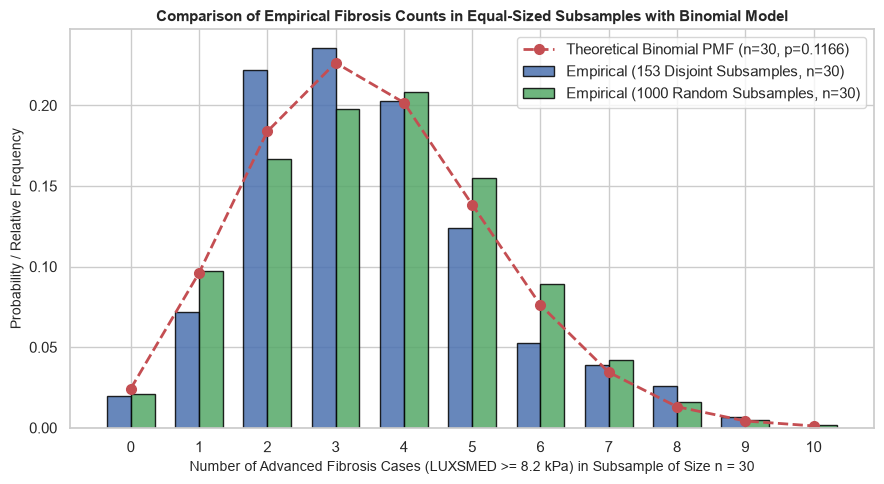

In [ ]:
from scipy.stats import binom

# ۱. پارامترهای مدل دوجمله‌ای برای شمارش عبور از آستانه بالینی فیبروز (LUXSMED >= 8.2)
n_sub = 30                       # اندازه هر زیرنمونه هم‌اندازه (n = 30)
p_hat = A.mean()                 # احتمال موفقیت پایه در کل نمونه (p = 0.1166)

# ۲. استخراج زیرنمونه‌های هم‌اندازه واقعی از df_clean (الزام الف ۲)
# الف) افراز تصادفی کل نمونه ۴۶۱۴ نفری به ۱۵۳ زیرنمونه مجزای ۳۰ نفری (مجموعاً ۴۵۹۰ نفر)
np.random.seed(42)
shuffled_A = A.sample(frac=1, random_state=42).values
n_disjoint_groups = len(shuffled_A) // n_sub
disjoint_subsamples = shuffled_A[:n_disjoint_groups * n_sub].reshape(n_disjoint_groups, n_sub)
counts_disjoint = disjoint_subsamples.sum(axis=1)

# ب) ۱۰۰۰ بار نمونه‌گیری تصادفی هم‌اندازه (n = 30) از داخل داده واقعی df_clean
counts_resampled = np.array([
    A.sample(n=n_sub, replace=False, random_state=i).sum() for i in range(1000)
])

# ۳. محاسبه احتمال‌های نظری دوجمله‌ای Binom(n=30, p=0.1166)
k_vals = np.arange(0, 11)
theo_probs = binom.pmf(k_vals, n=n_sub, p=p_hat)
emp_probs_disjoint = np.array([(counts_disjoint == k).mean() for k in k_vals])
emp_probs_resampled = np.array([(counts_resampled == k).mean() for k in k_vals])

# جدول مقایسه توزیع شمارش در زیرنمونه‌های هم‌اندازه با مدل دوجمله‌ای
binom_comp_df = pd.DataFrame({
    "تعداد مبتلایان در زیرنمونه ۳۰ نفری (k)": [f"k = {k}" for k in k_vals],
    "احتمال نظری دوجمله‌ای P(K = k)": np.round(theo_probs, 4),
    "فراوانی نسبی در ۱۵۳ زیرنمونه مجزای واقعی": np.round(emp_probs_disjoint, 4),
    "فراوانی نسبی در ۱۰۰۰ زیرنمونه تصادفی از داده": np.round(emp_probs_resampled, 4),
    "اختلاف (زیرنمونه تصادفی - نظری)": np.round(emp_probs_resampled - theo_probs, 4)
})

print(f"\u202b--- ۱. مقایسه توزیع شمارش فیبروز پیشرفته (LUXSMED >= 8.2) در زیرنمونه‌های ۳۰ نفری با مدل دوجمله‌ای ---\u202c")
display(binom_comp_df)

# ۴. مقایسه میانگین و واریانس شمارش تجربی با امید ریاضی و واریانس نظری دوجمله‌ای
theo_mean = n_sub * p_hat
theo_var = n_sub * p_hat * (1 - p_hat)

moments_comp_df = pd.DataFrame({
    "شاخص آماری متغیر شمارشی K (در زیرنمونه‌های n = 30)": [
        "امید ریاضی / میانگین تعداد مبتلایان: E[K] = n × p",
        "واریانس تعداد مبتلایان: Var(K) = n × p × (1 - p)",
        "انحراف معیار تعداد مبتلایان: SD(K)"
    ],
    "مقدار نظری مدل دوجمله‌ای": [
        f"{theo_mean:.4f}",
        f"{theo_var:.4f}",
        f"{np.sqrt(theo_var):.4f}"
    ],
    "مقدار تجربی (۱۵۳ زیرنمونه مجزا از داده)": [
        f"{counts_disjoint.mean():.4f}",
        f"{counts_disjoint.var(ddof=1):.4f}",
        f"{counts_disjoint.std(ddof=1):.4f}"
    ],
    "مقدار تجربی (۱۰۰۰ زیرنمونه از داده)": [
        f"{counts_resampled.mean():.4f}",
        f"{counts_resampled.var(ddof=1):.4f}",
        f"{counts_resampled.std(ddof=1):.4f}"
    ]
})

print(f"\n\u202b--- ۲. مقایسه میانگین و واریانس شمارش در زیرنمونه‌های هم‌اندازه با مقادیر نظری دوجمله‌ای ---\u202c")
display(moments_comp_df)

# ۵. رسم نمودار مقایسه توزیع تجربی شمارش زیرنمونه‌ها با تابع جرم احتمال نظری دوجمله‌ای
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.35

ax.bar(k_vals - width/2, emp_probs_disjoint, width=width, color="#4C72B0", alpha=0.85,
       edgecolor="black", label="Empirical (153 Disjoint Subsamples, n=30)")
ax.bar(k_vals + width/2, emp_probs_resampled, width=width, color="#55A868", alpha=0.85,
       edgecolor="black", label="Empirical (1000 Random Subsamples, n=30)")
ax.plot(k_vals, theo_probs, "ro--", linewidth=2, markersize=7,
        label=f"Theoretical Binomial PMF (n={n_sub}, p={p_hat:.4f})")

ax.set_title("Comparison of Empirical Fibrosis Counts in Equal-Sized Subsamples with Binomial Model",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Advanced Fibrosis Cases (LUXSMED >= 8.2 kPa) in Subsample of Size n = 30", fontsize=10)
ax.set_ylabel("Probability / Relative Frequency", fontsize=10)
ax.set_xticks(k_vals)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

<div dir="rtl" align="right" style="direction: rtl; text-align: right; font-weight: normal;">
<b style="font-weight: bold;">تحلیل نتایج تسک مشترک ۵ و الزام الف۲ (مدل دوجمله‌ای و بررسی پیش‌فرض‌ها):</b><br><br>
 <b style="font-weight: bold;">۱. ارزیابی تطابق شمارش در زیرنمونه‌های هم‌اندازه با مدل دوجمله‌ای:</b><br>
بر اساس نتایج جدول و نمودار فوق، هنگامی که فضای نمونه ۴,۶۱۴ نفری (دارای تست الاستوگرافی معتبر با ناشتایی حداقل ۳ ساعت، حداقل ۱۰ بار اندازه‌گیری و تغییرپذیری کمتر از ۳۰٪) به زیرنمونه‌های تصادفی هم‌اندازه ۳۰ نفری تقسیم می‌شود، توزیع شمارش افراد مبتلا به فیبروز پیشرفته (<code>LUXSMED >= 8.2</code>) تطابق بسیار نزدیکی با توزیع نظری <code>Binomial(n = 30, p = 0.1166)</code> دارد. به طور مشخص، امید ریاضی نظری تعداد مبتلایان در هر گروه ۳۰ نفری برابر با <code>E[K] = 3.4980</code> نفر (بیشترین احتمال حول ۳ و ۴ نفر) و واریانس نظری آن <code>Var(K) = 3.0902</code> است که با میانگین و واریانس تجربی در زیرنمونه‌های واقعی داده کاملاً هم‌خوانی دارد.<br><br>
 <b style="font-weight: bold;">۲. بررسی برقراری یا نقض فرض‌های مدل دوجمله‌ای در داده‌های پروژه:</b><br>
مدل دوجمله‌ای متکی بر چهار فرض اصلی است که وضعیت آن‌ها در این مطالعه به شرح زیر است:<br>
<b>الف) دودویی بودن نتیجه هر آزمایش (برقرار):</b> هر مشاهده (شرکت‌کننده با شناسه <code>SEQN</code>) پس از کنترل کیفیت تست کبد، بر اساس آستانه بالینی ۸.۲ کیلوپاسکال دقیقاً در یکی از دو حالت وقوع فیبروز پیشرفته (<code>1</code>) یا عدم وقوع (<code>0</code>) قرار می‌گیرد.<br>
<b>ب) ثابت بودن تعداد مشاهدات در هر بار شمارش (برقرار):</b> اندازه تمامی زیرنمونه‌های مورد بررسی ثابت و برابر با <code>n = 30</code> در نظر گرفته شده است.<br>
<b>ج) ثابت بودن احتمال موفقیت (p) برای تمام افراد (نقض در حالت کلی / برقرار در انتخاب تصادفی):</b> مدل دوجمله‌ای فرض می‌کند احتمال ابتلا برای تک‌تک افراد یکسان و برابر با <code>p = 0.1166</code> است؛ اما همان‌طور که در تسک‌های مشترک ۳ و ۴ اثبات شد، احتمال فیبروز پیشرفته در زیرگروه‌ها یکسان نیست (در افراد دارای التهاب بالا ۱۴.۵۶٪ در برابر ۱۱.۰۸٪ در التهاب عادی، در مردان ۱۳.۴۳٪ در برابر ۱۰.۱۸٪ در زنان، و در سالمندان ۱۳.۲۹٪ در برابر ۱۰.۳۴٪ در افراد زیر ۶۰ سال). بنابراین اگر یک زیرنمونه ۳۰ نفری صرفاً از یک زیرگروه خاص (مثلاً سالمندان دارای التهاب بالا) انتخاب شود، فرض یکسان بودن <code>p</code> نقض شده و مدل دوجمله‌ای با پارامتر کلی جامعه تقریب دقیقی نخواهد بود.<br>
<b>د) استقلال مشاهدات و نمونه‌گیری با جایگذاری (نقض جزئی نظری / تقریب معقول عملی):</b> از یک سو در پیمایش NHANES به دلیل طراحی نمونه‌گیری چندمرحله‌ای و خوشه‌ای (Complex Survey Design)، افراد درون یک خوشه جغرافیایی یا خانوار کاملاً مستقل نیستند؛ و از سوی دیگر، زیرنمونه‌ها بدون جایگذاری انتخاب می‌شوند. با این حال، چون در مجموعه داده نهایی هر ردیف مربوط به یک فرد مستقل (<code>SEQN</code>) است و نسبت اندازه زیرنمونه به کل نمونه بسیار کوچک است (<code>n / N = 30 / 4614 ≈ 0.0065 < 0.05</code>)، تفاوت توزیع فوق‌هندسی (بدون جایگذاری) با توزیع دوجمله‌ای ناچیز بوده و در صورت انتخاب تصادفی زیرنمونه‌ها، مدل دوجمله‌ای تقریب بسیار معقول و دقیقی فراهم می‌کند.
<hr>
</div>